# 05 Multivariate EDA

This notebook is a starting point for multivariate exploratory data analysis on the cleaned ElectraHub dataset.

Suggested flow:
- load the cleaned dataset
- inspect several-variable relationships
- compare grouped patterns across categories
- note key multivariate insights

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

dataset_path = Path("../data/processed/ElectraHub_Data_cleaned.csv")
df = pd.read_csv(dataset_path)

print(f"Dataset path: {dataset_path}")
print(f"Rows loaded: {len(df)}")
print(f"Columns loaded: {len(df.columns)}")

Dataset path: ../data/processed/ElectraHub_Data_cleaned.csv
Rows loaded: 3000
Columns loaded: 16


In [3]:
df.head()

  Region Product_Category  ... Popularity     Sales
0  South           Tablet  ...   Moderate  12265.79
1   West           Tablet  ...       High  20426.45
2   West           Mobile  ...       High  29827.18
3   East           Tablet  ...   Moderate  28211.95
4  North           Mobile  ...       High  29794.80

[5 rows x 16 columns]

In [4]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

Numeric columns: ['Product_Age_Months', 'Product_Price', 'Competitor_Price_Index', 'Advertising_Expenditure', 'Discount_Percentage', 'Campaign_Engagement_Score', 'Inventory_Level', 'Num_Reviews', 'Avg_Customer_Rating', 'Return_Rate', 'Length_Product_Description', 'Sales']
Categorical columns: ['Region', 'Product_Category', 'Campaign_Type', 'Popularity']


## Multivariate Relationships

Use this section to inspect several numeric variables at once and look for patterns across groups.

### Correlation Heatmap

The heatmap below shows correlations for all numerical variables, including Sales.

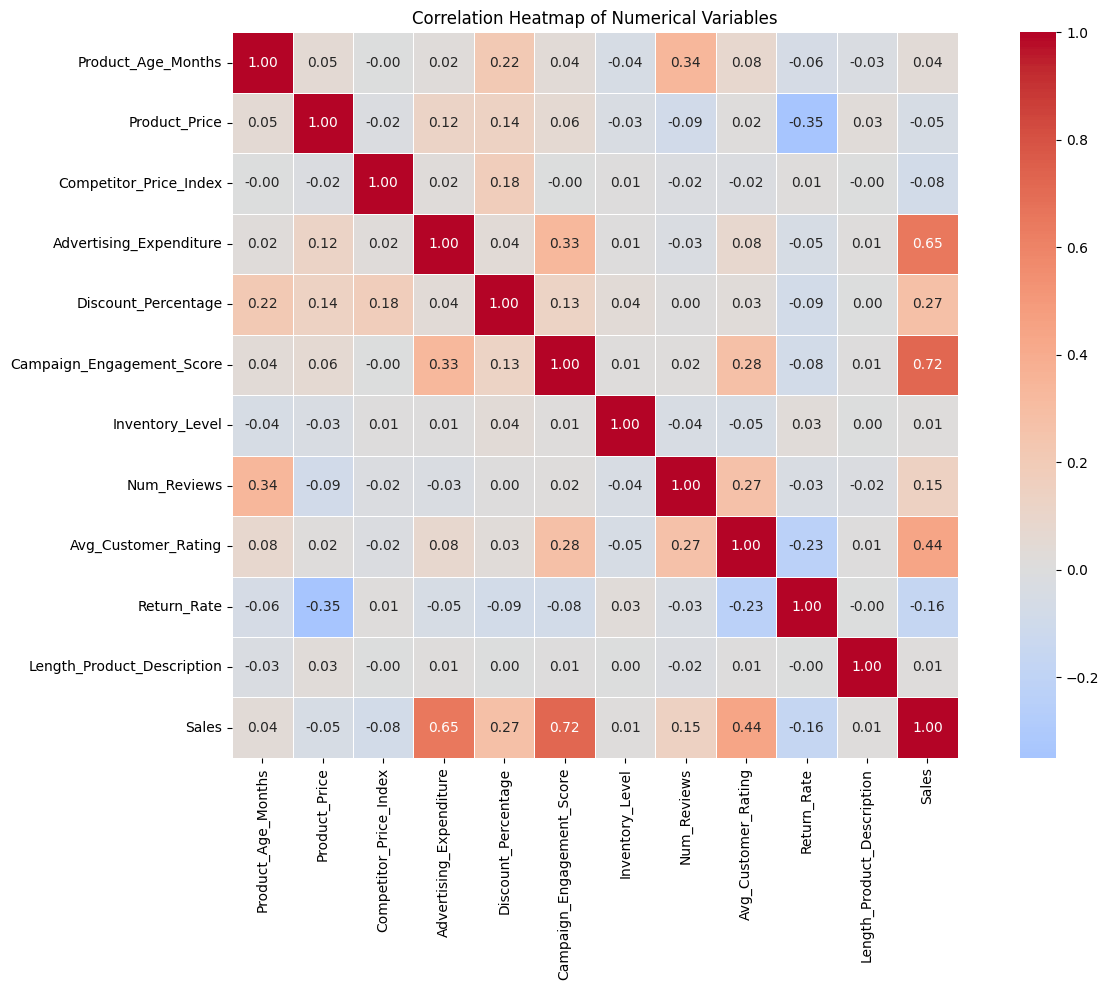

In [7]:
plt.figure(figsize=(14, 10))
corr_matrix = df[numeric_columns].corr()
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### Correlation with Sales

The chart below ranks numeric predictors by their correlation with Sales, from strongest positive to strongest negative.


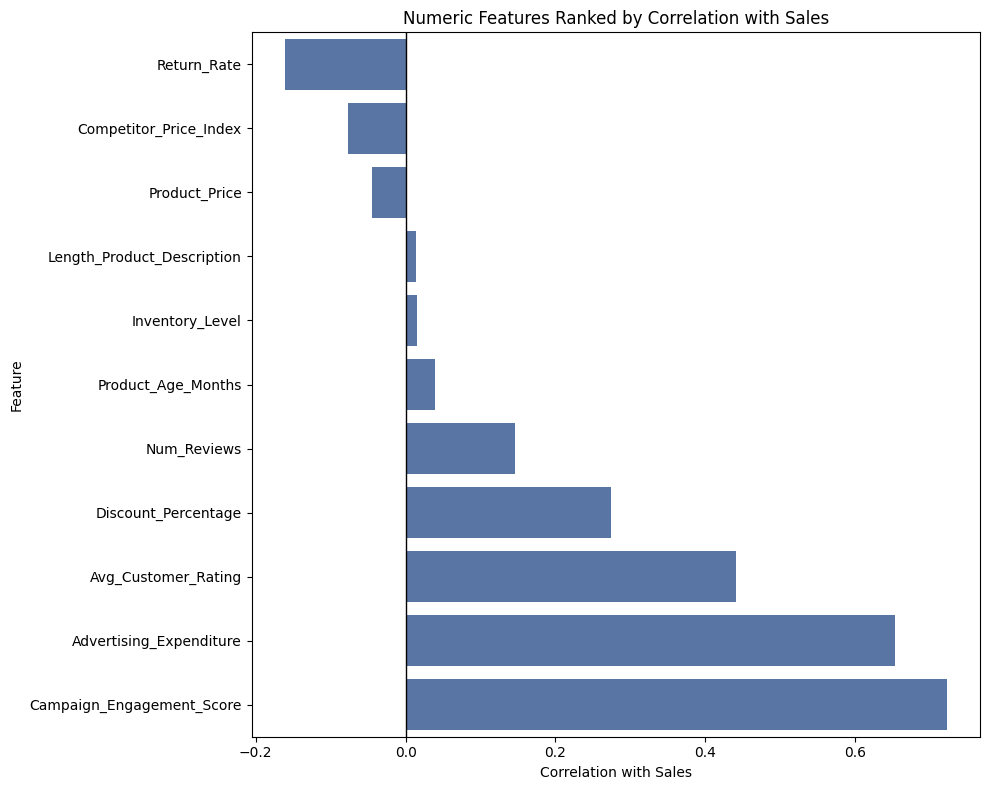

In [9]:
sales_correlations = df[numeric_columns].corr()["Sales"].drop("Sales").sort_values(ascending=True)

plt.figure(figsize=(10, 8))
ax = sns.barplot(x=sales_correlations.values, y=sales_correlations.index, color="#4C72B0")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Numeric Features Ranked by Correlation with Sales")
ax.set_xlabel("Correlation with Sales")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

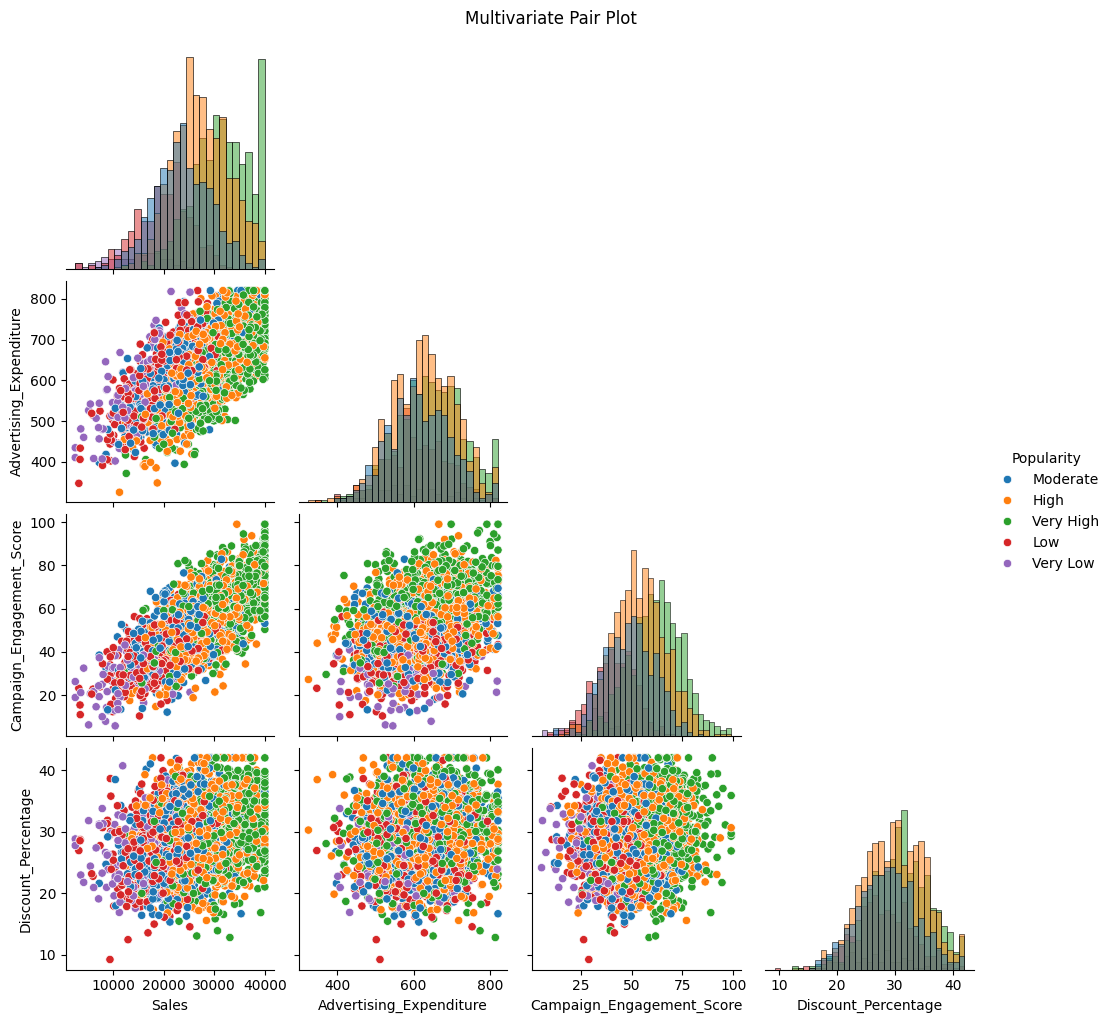

In [10]:
sample_columns = ["Sales", "Advertising_Expenditure", "Campaign_Engagement_Score", "Discount_Percentage", "Popularity"]
sns.pairplot(df[sample_columns], hue="Popularity", diag_kind="hist", corner=True)
plt.suptitle("Multivariate Pair Plot", y=1.02)
plt.show()

### Focused Pair Plot

The pairplot below focuses on Campaign_Engagement_Score, Advertising_Expenditure, Avg_Customer_Rating, Discount_Percentage, and Sales.


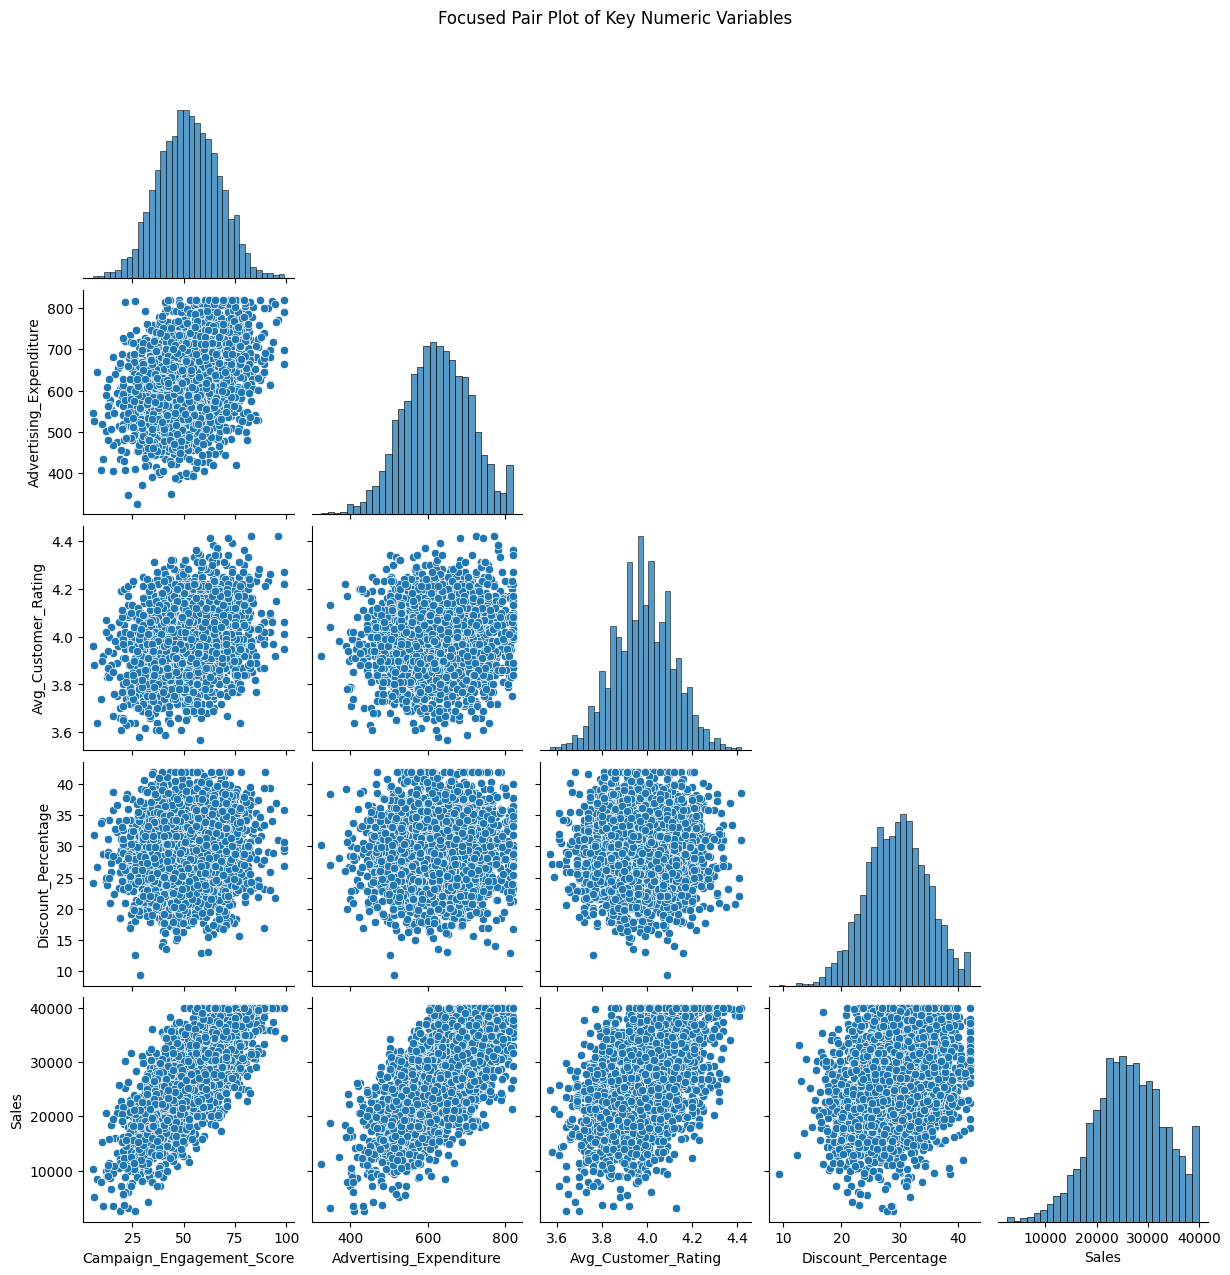

In [12]:
focused_columns = [
    "Campaign_Engagement_Score",
    "Advertising_Expenditure",
    "Avg_Customer_Rating",
    "Discount_Percentage",
    "Sales",
]

sns.pairplot(df[focused_columns], diag_kind="hist", corner=True)
plt.suptitle("Focused Pair Plot of Key Numeric Variables", y=1.02)
plt.show()

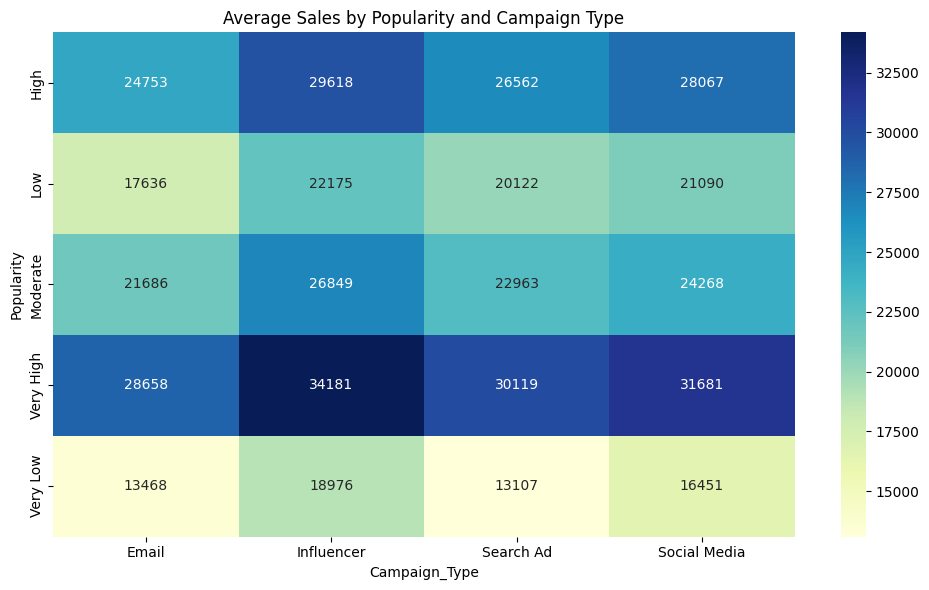

In [13]:
grouped_sales = df.pivot_table(
    index="Popularity",
    columns="Campaign_Type",
    values="Sales",
    aggfunc="mean",
)

plt.figure(figsize=(10, 6))
sns.heatmap(grouped_sales, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Average Sales by Popularity and Campaign Type")
plt.tight_layout()
plt.show()

### Average Sales by Campaign Type and Region

The grouped bar chart below compares average Sales across Campaign_Type, with bars grouped by Region.


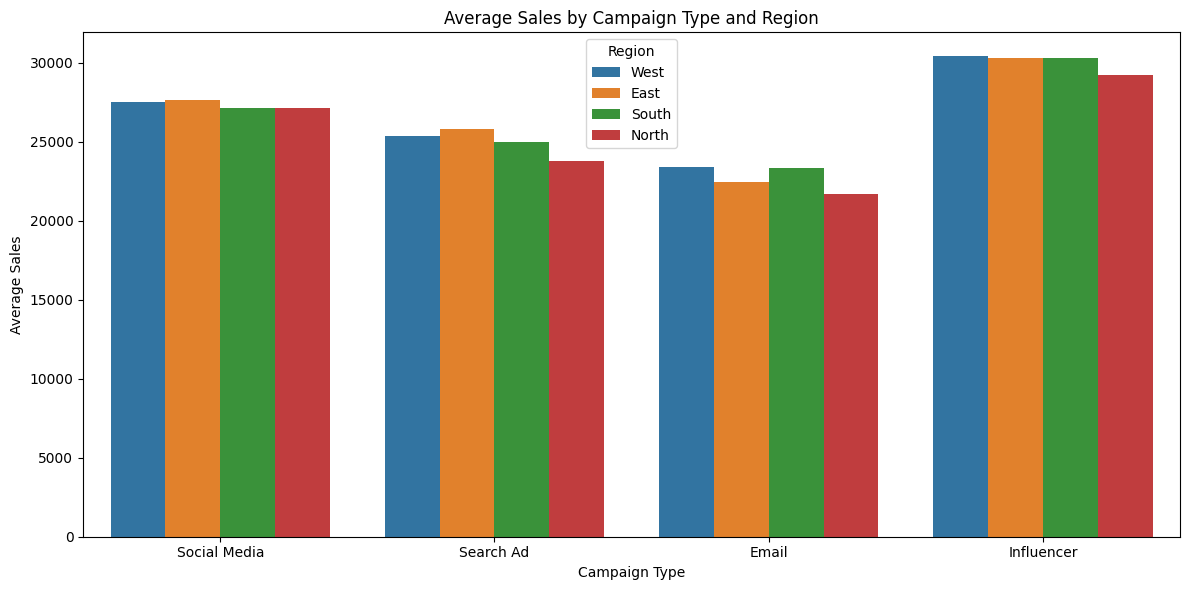

In [15]:
campaign_order = df["Campaign_Type"].value_counts().index.tolist()
region_order = df["Region"].value_counts().index.tolist()
grouped_sales_by_region = df.groupby(["Campaign_Type", "Region"], as_index=False)["Sales"].mean()

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=grouped_sales_by_region, x="Campaign_Type", y="Sales", hue="Region", order=campaign_order, hue_order=region_order)
ax.set_title("Average Sales by Campaign Type and Region")
ax.set_xlabel("Campaign Type")
ax.set_ylabel("Average Sales")
plt.tight_layout()
plt.show()

### Sales by Popularity and Product Category

The box plot below shows Sales by Popularity level, separated into Mobile and Tablet groups.


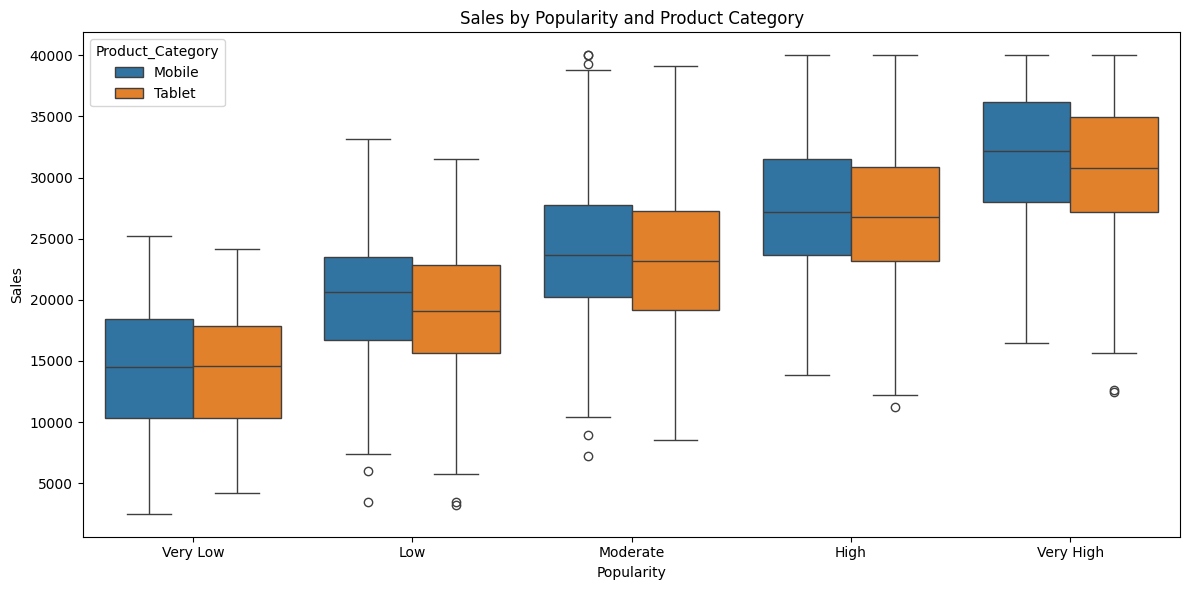

In [17]:
popularity_order = ["Very Low", "Low", "Moderate", "High", "Very High"]
category_order = ["Mobile", "Tablet"]

plt.figure(figsize=(12, 6))
ax = sns.boxplot(data=df, x="Popularity", y="Sales", hue="Product_Category", order=popularity_order, hue_order=category_order)
ax.set_title("Sales by Popularity and Product Category")
ax.set_xlabel("Popularity")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.show()

## Findings

Document your main multivariate insights here.